# Notebook 07 EfficientNetV2 S at 192px

Train **one** new model for eight epochs on the saved split 1337: 54,098 training images and 9,547 validation images. The aim is to test whether a different model configuration can help our current **0.9806** ensemble. Its score is unknown.

**Inputs:** attach the original **Competition** dataset and upload `07_effnet192_inputs.zip` as a **private** Kaggle dataset. The small pack contains the completed metadata audit, exact split IDs and existing validation predictions. It contains no test labels or model weights. Both an unpacked dataset and the ZIP itself are supported.

**Settings:** GPU enabled and Internet enabled. Use the existing Kaggle package environment; this notebook does not install or upgrade packages. A Hugging Face token is optional. If using the existing secret, change `USE_HF_SECRET` to `True` in the first cell and enable the secret named `kaggle-assignment3`.

Run All applies to **this notebook only**. It reuses the audit, trains the new model, compares validation errors, exports clean/flip-averaged test probabilities and creates a backup ZIP. It does not select or submit a prediction CSV. Training, validation and test inference each show progress.

The best checkpoint is selected by clean validation accuracy, with ordinary cross-entropy as the tie breaker. Every completed epoch also saves the optimizer, scheduler, AMP scaler and random states. A rerun resumes from the last completed epoch; an interrupted epoch is repeated. To resume after a new Kaggle session, attach this notebook's saved output files. Prediction passes restart from the beginning if interrupted; completed verified passes are reused.

This is a **new configuration**, not a pure resolution ablation of the original EfficientNet run. It also uses geometry augmentation and the pretrained model's resolved normalisation (mean/std 0.5 per channel). The original 128px run used ImageNet mean/std. Our chosen 192px square bilinear resize is recorded explicitly, rather than using the model card's default crop/resize. All comparisons preserve the same held-out IDs; full-data models are excluded from holdout scoring. These are reused-split diagnostics, not an independent validation score for the winning seven-model ensemble.

Allow roughly **1-3 hours**, depending on GPU and image loading. The first epoch gives a better runtime estimate. Pretrained weights: [official timm model card](https://huggingface.co/timm/tf_efficientnetv2_s.in21k_ft_in1k).

In [1]:
# Optional authentication. The token value is never printed or saved.
import os
USE_HF_SECRET = False
if USE_HF_SECRET:
    from kaggle_secrets import UserSecretsClient
    os.environ['HF_TOKEN'] = UserSecretsClient().get_secret('kaggle-assignment3')

from pathlib import Path
from io import BytesIO
import copy, hashlib, json, math, platform, random, shutil, time, zipfile
import numpy as np
import pandas as pd
from PIL import Image
import PIL
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from IPython.display import display

# Normally leave these paths unset; discovery checks for ambiguity.
BASE = None
INPUT_PACK = None   # An unpacked pack directory or 07_effnet192_inputs.zip.
RECOVERY_DIR = None # Optional directory containing this run's saved last.pth/best.pth.
MODEL_NAME = 'tf_efficientnetv2_s.in21k_ft_in1k'
RUN_NAME = 'efficientnetv2s_192_geometry_val1337_seed42'
OUT = Path('/kaggle/working/efficientnetv2s_192_validation')
RUN_DIR = OUT/RUN_NAME
TRAIN_SEED = 42
SPLIT_SEED = 1337
EPOCHS = 8
BATCH_SIZE = 64
NUM_WORKERS = 2
CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
EXPECTED_LABEL_SHA = '94124e856786379a9c1e9c8c7ba4599a9f27fe8dc6ea4165dc4afc55024d41a3'
EXPECTED_SPLIT_HASH = '842af9ee7beb6fe8c85fd55163deeb15cf8a5c778506c075f987e9b9ed9889b6'
assert torch.cuda.is_available(), 'Enable a Kaggle GPU before starting this notebook.'
assert MODEL_NAME in timm.list_models(pretrained=True), 'The recorded pretrained model is unavailable; review timm without upgrading it automatically.'
device=torch.device('cuda')
versions=dict(python=platform.python_version(),torch=str(torch.__version__),
              torchvision=str(torchvision.__version__),timm=str(timm.__version__),
              numpy=str(np.__version__),pandas=str(pd.__version__),pillow=str(PIL.__version__))
probe=timm.create_model(MODEL_NAME,pretrained=False,num_classes=len(CLASSES))
resolved=resolve_model_data_config(probe)
assert np.allclose(resolved['mean'],[.5]*3) and np.allclose(resolved['std'],[.5]*3), 'Pretrained normalisation changed; review before training.'
del probe
print('GPU:',torch.cuda.get_device_name(0),'| versions:',versions,flush=True)
print('One EfficientNetV2-S run: 192px, split 1337, eight epochs, batch 64.',flush=True)


GPU: Tesla T4 | versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.29', 'numpy': '2.1.3', 'pandas': '2.3.3', 'pillow': '12.3.0'}
One EfficientNetV2-S run: 192px, split 1337, eight epochs, batch 64.


## 1 Load the verified metadata and exact split

This checks the supplied cache and a fixed sample of original training files. It does not repeat the full image audit. The cache assumes the same original competition images; re-audit if those files have been replaced. The sample-submission class column is never used as ground truth.

In [2]:
EXPECTED_PACK_MANIFEST_SHA = '12d4369226ddacaf9fd1cf6f34956a7755f1b0c9c51b0ef589eaeee2af418a3b'

def sha_bytes(raw): return hashlib.sha256(raw).hexdigest()

def sha_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def read_pack(location):
    location=Path(location)
    if location.is_dir():
        def read(name): return (location/name).read_bytes()
    else:
        def read(name):
            with zipfile.ZipFile(location) as z: return z.read(name)
    manifest_raw=read('07_effnet192_inputs_manifest.json')
    assert sha_bytes(manifest_raw)==EXPECTED_PACK_MANIFEST_SHA, 'The input-pack manifest differs from the checked experiment pack.'
    manifest=json.loads(manifest_raw)
    content={}
    for name,record in manifest['files'].items():
        raw=read(name)
        assert len(raw)==record['bytes'] and sha_bytes(raw)==record['sha256'], f'Input-pack file failed verification: {name}'
        content[name]=raw
    return manifest,content,manifest_raw

def image_folder(base,kind):
    for path in [base/kind/kind,base/kind]:
        if (path/'00001.jpg').is_file(): return path
    raise FileNotFoundError(f'Missing {kind} images below {base}')

def probability_metrics(y,p):
    return dict(errors=int((p.argmax(1)!=y).sum()),accuracy=float((p.argmax(1)==y).mean()),
                nll=float(-np.log(p[np.arange(len(y)),y].clip(1e-12,1)).mean()))

def check_probabilities(p,rows):
    assert p.shape==(rows,len(CLASSES)) and np.isfinite(p).all() and (p>=0).all()
    assert np.allclose(p.sum(1),1,atol=2e-5,rtol=0)

def validate_frames(content,official_labels):
    meta=pd.read_csv(BytesIO(content['train_metadata_clean.csv']))
    tr=pd.read_csv(BytesIO(content['train_split_1337.csv']))
    va=pd.read_csv(BytesIO(content['val_split_1337.csv']))
    assert len(meta)==63645 and meta.image_id.is_unique and meta.md5.is_unique
    assert len(tr)==54098 and len(va)==9547 and tr.image_id.is_unique and va.image_id.is_unique
    assert set(tr.image_id).isdisjoint(set(va.image_id))
    assert set(tr.image_id)|set(va.image_id)==set(meta.image_id)
    official=official_labels.set_index('image_id')['class']
    assert np.array_equal(meta['class'],official.loc[meta.image_id])
    lookup=meta.set_index('image_id')
    for frame in [tr,va]:
        assert np.array_equal(frame['class'],lookup.loc[frame.image_id,'class'])
    assert set(lookup.loc[tr.image_id,'md5']).isdisjoint(set(lookup.loc[va.image_id,'md5']))
    assert sha_bytes(va.image_id.to_numpy(dtype='<i8').tobytes())==EXPECTED_SPLIT_HASH
    tr=tr.copy();va=va.copy()
    tr['label']=tr['class'].map(CLASS_TO_IDX).astype('int64')
    va['label']=va['class'].map(CLASS_TO_IDX).astype('int64')
    return meta,tr,va

if INPUT_PACK is None:
    pack_options=list(Path('/kaggle/input').rglob('07_effnet192_inputs_manifest.json'))
    pack_options=[p.parent for p in pack_options]
    if not pack_options: pack_options=list(Path('/kaggle/input').rglob('07_effnet192_inputs.zip'))
    assert len(pack_options)==1, f'Attach the private 07_effnet192_inputs pack or set INPUT_PACK explicitly. Found: {pack_options}'
    INPUT_PACK=pack_options[0]
pack,pack_files,pack_manifest_raw=read_pack(INPUT_PACK)
if BASE is None:
    data_options=[]
    for path in Path('/kaggle/input').rglob('train_labels.csv'):
        if not (path.parent/'sample_submission.csv').is_file(): continue
        try: image_folder(path.parent,'train');image_folder(path.parent,'test')
        except FileNotFoundError: continue
        data_options.append(path.parent)
    assert len(data_options)==1, f'Attach Competition or set BASE explicitly. Found: {data_options}'
    BASE=data_options[0]
BASE=Path(BASE)
TRAIN_DIR=image_folder(BASE,'train');TEST_DIR=image_folder(BASE,'test')
assert sha_file(BASE/'train_labels.csv')==EXPECTED_LABEL_SHA, 'The label file differs from the previously audited competition.'
labels=pd.read_csv(BASE/'train_labels.csv')
sample=pd.read_csv(BASE/'sample_submission.csv')
assert labels.columns.tolist()==sample.columns.tolist()==['image_id','class']
assert len(labels)==63660 and labels.image_id.is_unique and not labels.isna().any().any()
assert len(sample)==29443 and sample.image_id.is_unique and not sample.image_id.isna().any()
assert set(labels['class'])==set(CLASSES)
meta,train_df,val_df=validate_frames(pack_files,labels)
val_ids=val_df.image_id.to_numpy(dtype='int64');y=val_df.label.to_numpy(dtype='int64')
test_ids=sample.image_id.to_numpy(dtype='int64')
assert sha_bytes(test_ids.astype('<i8').tobytes())==pack['test_id_order_sha256'], 'Test IDs differ from the original sample order.'
refs={}
for name in ['control','geometry','v2']:
    ref_cfg=json.loads(pack_files[f'reference_{name}_config.json'])
    assert ref_cfg['split_hash']==EXPECTED_SPLIT_HASH and ref_cfg['split_seed']==1337 and not ref_cfg['full_data']
    for view in ['clean','tta']:
        with np.load(BytesIO(pack_files[f'reference_{name}_val_{view}.npz']),allow_pickle=False) as a:
            assert a['classes'].tolist()==CLASSES and str(a['split_hash'])==EXPECTED_SPLIT_HASH
            assert np.array_equal(a['image_id'],val_ids) and np.array_equal(a['labels'],y)
            p=a['probs'].copy()
        check_probabilities(p,len(y))
        assert probability_metrics(y,p)['errors']==pack['reference_errors'][f'{name}_{view}']
        refs[(name,view)]=p
# Verify original image bytes for the same fixed sample on each run.
for r in meta.sample(n=32,random_state=42).itertuples(index=False):
    raw=(TRAIN_DIR/f'{int(r.image_id):05d}.jpg').read_bytes()
    assert hashlib.md5(raw).hexdigest()==r.md5, 'An input image differs from the original audit.'
print('Verified:',len(train_df),'training /',len(val_df),'validation /',len(sample),'test images.',flush=True)
print('Reused the completed audit and exact split 1337; existing reference errors:',pack['reference_errors'],flush=True)


Verified: 54098 training / 9547 validation / 29443 test images.
Reused the completed audit and exact split 1337; existing reference errors: {'control_clean': 26, 'control_tta': 26, 'geometry_clean': 33, 'geometry_tta': 29, 'v2_clean': 34, 'v2_tta': 29}


## 2 Model settings and image loading

The geometry and standard augmentations come from Notebook 04. The loader uses two workers and pinned memory. Workers restart each epoch so saved generator/random states can be restored at epoch boundaries. Eight epochs are fixed in advance; the learning-rate schedule advances only when AMP makes an optimizer update.

In [3]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)

class RandomDownscale:
    def __init__(self, p=.3): self.p=p
    def __call__(self, img):
        if random.random() < self.p:
            target=random.randint(16,48); short=min(img.size)
            if short > target:
                scale=target/short
                img=img.resize((max(1,round(img.width*scale)), max(1,round(img.height*scale))),
                               Image.Resampling.BILINEAR)
        return img

class AxisPad:
    def __init__(self, p=.5, max_fraction=.15, fixed=None):
        self.p, self.max_fraction, self.fixed = p, max_fraction, fixed
    def __call__(self, img):
        if self.fixed is None:
            if random.random() >= self.p: return img
            fx=random.uniform(0,self.max_fraction)
            fy=random.uniform(0,self.max_fraction)
        else:
            fx,fy=self.fixed
        w,h=img.size
        px,py=round(w*fx),round(h*fy)
        # This runs after square resizing: padding is always smaller than either side.
        return TF.pad(img, [px,py,px,py], padding_mode='reflect')

def transforms_for(cfg, training=False, stress=None):
    s=cfg['size']; ops=[]
    if training: ops.append(RandomDownscale(cfg['downscale_p']))
    ops.append(T.Resize((s,s), interpolation=T.InterpolationMode.BILINEAR, antialias=True))
    if training and cfg['geometry']:
        ops.extend([AxisPad(), T.Resize((s,s), antialias=True)])
    if stress:
        fixed={'wide':(0,.15), 'tall':(.15,0)}[stress]
        ops.extend([AxisPad(fixed=fixed), T.Resize((s,s), antialias=True)])
    if training:
        ops.extend([T.RandomHorizontalFlip(.5),
                    T.RandomAffine(degrees=10, translate=(.05,.05), scale=(.9,1.1)),
                    T.ColorJitter(brightness=.3, contrast=.3, saturation=.2)])
    ops.extend([T.ToTensor(), T.Normalize(cfg['mean'],cfg['std'])])
    return T.Compose(ops)

class Images(Dataset):
    def __init__(self, frame, folder, transform):
        self.frame=frame.reset_index(drop=True); self.folder=folder; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; image_id=int(r['image_id'])
        with Image.open(self.folder/f'{image_id:05d}.jpg') as im:
            x=self.transform(im.convert('RGB'))
        y=int(r['label']) if 'label' in self.frame.columns else -1
        return x,y,image_id

PIPELINE_SOURCE_SHA = 'f04bbb60499628ed7827606f874d9707ddbee854a8f0400e51de17da26150be1'


In [4]:
CFG=dict(model=MODEL_NAME,size=192,geometry=True,epochs=EPOCHS,batch_size=BATCH_SIZE,
         lr=3e-4,weight_decay=.05,label_smoothing=.1,downscale_p=.3,
         mean=list(map(float,resolved['mean'])),std=list(map(float,resolved['std'])),
         split_seed=SPLIT_SEED,train_seed=TRAIN_SEED,full_data=False,classes=CLASSES,
         label_sha256=EXPECTED_LABEL_SHA,split_hash=EXPECTED_SPLIT_HASH,
         input_pack_manifest_sha256=EXPECTED_PACK_MANIFEST_SHA,
         experiment_version='07-effnet192-v1',pipeline_source_sha256=PIPELINE_SOURCE_SHA,
         augmentation=dict(downscale_p=.3,downscale_short_side=[16,48],geometry_p=.5,
                           geometry_max_fraction_per_side=.15,horizontal_flip_p=.5,
                           affine_degrees=10,translation_per_axis=.05,scale=[.9,1.1],
                           brightness=.3,contrast=.3,saturation=.2),
         resize_interpolation='bilinear',antialias=True,num_workers=NUM_WORKERS,
         persistent_workers=False,drop_last=False,amp='float16',versions=versions)
CFG_SHA=sha_bytes(json.dumps(CFG,sort_keys=True).encode())

def atomic_json(path,data):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    temp.write_text(json.dumps(data,indent=2)+'\n');os.replace(temp,path)

def atomic_torch(path,data):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    torch.save(data,temp);os.replace(temp,path)

def make_loader(frame,folder,training=False):
    generator=torch.Generator().manual_seed(TRAIN_SEED)
    loader=DataLoader(Images(frame,folder,transforms_for(CFG,training=training)),
                      batch_size=BATCH_SIZE,shuffle=training,drop_last=False,
                      num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False,
                      worker_init_fn=seed_worker,generator=generator)
    return loader,generator

def current_random_state(generator):
    n=np.random.get_state()
    return dict(python=random.getstate(),numpy=(n[0],n[1].tolist(),n[2],n[3],n[4]),
                torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state(device),
                loader=generator.get_state())

def restore_random_state(state,generator):
    random.setstate(state['python'])
    n=state['numpy'];np.random.set_state((n[0],np.array(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    torch.set_rng_state(state['torch']);torch.cuda.set_rng_state(state['cuda'],device)
    generator.set_state(state['loader'])

def schedule_factor(step,warmup_steps,total_steps):
    if step<warmup_steps: return (step+1)/warmup_steps
    progress=(step-warmup_steps)/max(1,total_steps-warmup_steps)
    return .5*(1+math.cos(math.pi*min(progress,1)))

@torch.inference_mode()
def predict_views(model,loader,description,flip=False):
    model.eval();clean=[];tta=[];ys=[];ids=[]
    for x,target,image_id in tqdm(loader,desc=description,leave=True):
        x=x.to(device,non_blocking=True)
        with torch.autocast('cuda',dtype=torch.float16):
            logits=model(x)
        p=torch.softmax(logits.float(),dim=1)
        clean.append(p.cpu().numpy())
        if flip:
            with torch.autocast('cuda',dtype=torch.float16):
                flipped_logits=model(x.flip(-1))
            q=torch.softmax(flipped_logits.float(),dim=1)
            tta.append(((p+q)/2).cpu().numpy())
        ys.append(target.numpy());ids.append(image_id.numpy())
    return np.concatenate(clean),None if not flip else np.concatenate(tta),np.concatenate(ys),np.concatenate(ids)

def restore_saved_run():
    if (RUN_DIR/'config.json').exists():
        assert json.loads((RUN_DIR/'config.json').read_text())==dict(config_sha256=CFG_SHA,config=CFG), 'Existing run settings differ; they will not be overwritten.'
        if (RUN_DIR/'last.pth').exists() or (RUN_DIR/'training_complete.json').exists(): return
    existing=[p for p in RUN_DIR.glob('*') if p.suffix!='.tmp' and p.name!='config.json'] if RUN_DIR.exists() else []
    assert not existing, 'This local run directory lacks its config. Preserve it and review before restarting.'
    if RECOVERY_DIR is not None:
        choices=[Path(RECOVERY_DIR)]
    else:
        choices=[p.parent for p in Path('/kaggle/input').rglob('config.json') if p.parent.name==RUN_NAME]
    assert len(choices)<=1, f'Multiple saved Notebook 07 runs found. Set RECOVERY_DIR explicitly: {choices}'
    if choices:
        source=choices[0]
        record=json.loads((source/'config.json').read_text())
        assert record['config_sha256']==CFG_SHA, 'Saved run settings/environment differ; preserve that run and review the config.'
        assert (source/'last.pth').is_file() or (source/'training_complete.json').is_file(), 'Saved run has no recoverable epoch checkpoint.'
        shutil.copytree(source,RUN_DIR,dirs_exist_ok=True)
        print('Restored saved Notebook 07 files from:',source,flush=True)

restore_saved_run()
RUN_DIR.mkdir(parents=True,exist_ok=True)
record=dict(config_sha256=CFG_SHA,config=CFG)
if (RUN_DIR/'config.json').exists():
    assert json.loads((RUN_DIR/'config.json').read_text())==record, 'Existing run has different settings. It will not be overwritten.'
else: atomic_json(RUN_DIR/'config.json',record)
OUT.mkdir(parents=True,exist_ok=True)
for name in ['train_split_1337.csv','val_split_1337.csv']:
    target=OUT/name
    if target.exists(): assert target.read_bytes()==pack_files[name]
    else: target.write_bytes(pack_files[name])
atomic_json(OUT/'input_pack_manifest.json',pack)
print('Pretrained normalisation:',CFG['mean'],CFG['std'],'| output:',OUT,flush=True)


Pretrained normalisation: [0.5, 0.5, 0.5] [0.5, 0.5, 0.5] | output: /kaggle/working/efficientnetv2s_192_validation


## 3 Train or resume the new model

The optimizer, scheduler and RNG states are saved in `last.pth` after each completed epoch. It also contains the best model state, so a partially written separate best file can be recovered. `best.pth` is the model selected by clean validation, not necessarily the final epoch. Keep saved output files if ending the Kaggle session.

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

START: one new EfficientNetV2-S model, eight epochs. Initial pretrained download may take time.


EfficientNet 192 epoch 1/8:   0%|          | 0/846 [00:00<?, ?it/s]

Clean validation epoch 1/8:   0%|          | 0/150 [00:00<?, ?it/s]

...

Clean validation epoch 7/8:   0%|          | 0/150 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.4782581640954, 'train_acc': 0.997060889496839, 'val_acc': 0.9957054572116896, 'val_nll': 0.10987367480993271, 'val_errors': 41, 'skipped_updates': 2, 'successful_updates': 5920, 'seconds': 278.3}


EfficientNet 192 epoch 8/8:   0%|          | 0/846 [00:00<?, ?it/s]

Clean validation epoch 8/8:   0%|          | 0/150 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.4759131636217282, 'train_acc': 0.9979481681393028, 'val_acc': 0.9956007122656332, 'val_nll': 0.10727144777774811, 'val_errors': 42, 'skipped_updates': 2, 'successful_updates': 6766, 'seconds': 278.4}
Training complete. Loaded best checkpoint epoch 7


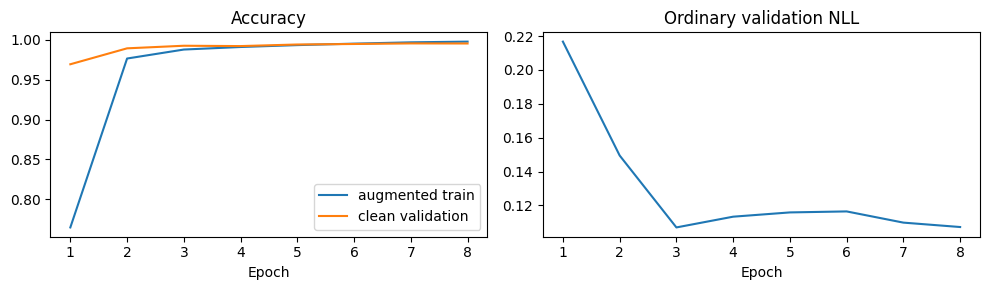

In [5]:
def train_or_resume():
    seed_all(TRAIN_SEED)
    completed=RUN_DIR/'training_complete.json';last_path=RUN_DIR/'last.pth';best_path=RUN_DIR/'best.pth'
    if completed.exists():
        done=json.loads(completed.read_text())
        assert done['config_sha256']==CFG_SHA and done['completed_epochs']==EPOCHS
        assert sha_file(best_path)==done['best_sha256']
        assert sha_file(RUN_DIR/'history.csv')==done['history_sha256']
        saved=torch.load(best_path,map_location='cpu',weights_only=True)
        assert saved['config_sha256']==CFG_SHA and saved['config']==CFG
        model=timm.create_model(MODEL_NAME,pretrained=False,num_classes=len(CLASSES)).to(device)
        model.load_state_dict(saved['model'])
        history=pd.read_csv(RUN_DIR/'history.csv')
        assert history.epoch.tolist()==list(range(1,EPOCHS+1))
        print('Reused completed training. Selected epoch:',saved['epoch'],flush=True)
        return model,history
    assert last_path.exists() or not (best_path.exists() or (RUN_DIR/'history.csv').exists()), 'A partial run has no last.pth; preserve it for review before retraining.'
    resume=last_path.exists()
    model=timm.create_model(MODEL_NAME,pretrained=not resume,num_classes=len(CLASSES)).to(device)
    train_loader,train_generator=make_loader(train_df,TRAIN_DIR,training=True)
    val_loader,_=make_loader(val_df,TRAIN_DIR)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])
    steps=len(train_loader);total=EPOCHS*steps
    scheduler=torch.optim.lr_scheduler.LambdaLR(opt,lambda step:schedule_factor(step,steps,total))
    scaler=torch.amp.GradScaler('cuda')
    criterion=nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    history=[];best_rank=(-1.,-float('inf'));best_epoch=None;best_state=None;best_metrics=None
    skipped=0;updates=0;start_epoch=1
    if resume:
        saved=torch.load(last_path,map_location='cpu',weights_only=True)
        assert saved['config_sha256']==CFG_SHA and saved['config']==CFG
        assert 1<=saved['epoch']<=EPOCHS
        model.load_state_dict(saved['model']);opt.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler']);scaler.load_state_dict(saved['scaler'])
        history=saved['history'];best_rank=tuple(saved['best_rank']);best_epoch=saved['best_epoch']
        best_state=saved['best_model'];best_metrics=saved['best_metrics']
        assert [r['epoch'] for r in history]==list(range(1,saved['epoch']+1))
        skipped=saved['skipped_updates'];updates=saved['successful_updates'];start_epoch=saved['epoch']+1
        restore_random_state(saved['random_state'],train_generator)
        del saved
        print('Resuming after completed epoch',start_epoch-1,'of',EPOCHS,flush=True)
    else:
        print('START: one new EfficientNetV2-S model, eight epochs. Initial pretrained download may take time.',flush=True)
    for epoch in range(start_epoch,EPOCHS+1):
        start=time.perf_counter();model.train();loss_sum=0.;correct=0;n=0
        bar=tqdm(train_loader,desc=f'EfficientNet 192 epoch {epoch}/{EPOCHS}',leave=True)
        for x,target,_ in bar:
            x=x.to(device,non_blocking=True);target=target.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(x);loss=criterion(logits,target)
            assert torch.isfinite(loss).item(), 'Non-finite training loss. Last completed epoch remains saved.'
            before=scaler.get_scale()
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=before: scheduler.step();updates+=1
            else: skipped+=1
            loss_sum+=float(loss.item())*len(target)
            correct+=int((logits.argmax(1)==target).sum().item());n+=len(target)
            bar.set_postfix(loss=f'{loss_sum/n:.4f}',lr=f'{opt.param_groups[0]["lr"]:.2g}')
        p,_,target,ids=predict_views(model,val_loader,f'Clean validation epoch {epoch}/{EPOCHS}')
        assert np.array_equal(ids,val_ids) and np.array_equal(target,y)
        check_probabilities(p,len(y));m=probability_metrics(y,p)
        rank=(m['accuracy'],-m['nll'])
        current_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        if rank>best_rank:
            best_rank=rank;best_epoch=epoch;best_state=current_state;best_metrics=m
        row=dict(epoch=epoch,train_loss=loss_sum/n,train_acc=correct/n,val_acc=m['accuracy'],
                 val_nll=m['nll'],val_errors=m['errors'],skipped_updates=skipped,
                 successful_updates=updates,seconds=round(time.perf_counter()-start,1))
        history.append(row)
        payload=dict(config_sha256=CFG_SHA,config=CFG,epoch=epoch,model=current_state,
                     optimizer=opt.state_dict(),scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
                     history=history,best_model=best_state,best_rank=best_rank,best_epoch=best_epoch,
                     best_metrics=best_metrics,skipped_updates=skipped,successful_updates=updates,
                     random_state=current_random_state(train_generator))
        # This is the authoritative epoch commit. CSV/best files can be rebuilt from it.
        atomic_torch(last_path,payload)
        del payload,current_state
        pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
        atomic_torch(best_path,dict(model=best_state,config=CFG,config_sha256=CFG_SHA,
                                   epoch=best_epoch,validation=best_metrics))
        print(row,flush=True)
    assert len(history)==EPOCHS and best_state is not None
    pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
    atomic_torch(best_path,dict(model=best_state,config=CFG,config_sha256=CFG_SHA,
                               epoch=best_epoch,validation=best_metrics))
    atomic_json(completed,dict(config_sha256=CFG_SHA,completed_epochs=EPOCHS,best_epoch=best_epoch,
                               best_sha256=sha_file(best_path),history_sha256=sha_file(RUN_DIR/'history.csv')))
    model.load_state_dict(best_state)
    del train_loader,val_loader,opt,scheduler,scaler,best_state
    torch.cuda.empty_cache()
    print('Training complete. Loaded best checkpoint epoch',best_epoch,flush=True)
    return model,pd.DataFrame(history)

model,history=train_or_resume()
fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(history.epoch,history.train_acc,label='augmented train')
axs[0].plot(history.epoch,history.val_acc,label='clean validation')
axs[0].set_title('Accuracy');axs[0].set_xlabel('Epoch');axs[0].legend()
axs[1].plot(history.epoch,history.val_nll)
axs[1].set_title('Ordinary validation NLL');axs[1].set_xlabel('Epoch')
plt.tight_layout();fig.savefig(RUN_DIR/'learning_curves.png',dpi=160);plt.show();plt.close(fig)


## 4 Compare validation errors on the same held-out images

Clean and horizontal-flip averaged predictions are saved with IDs, labels, class order and the selected checkpoint fingerprint. The comparison includes paired mistakes, not only overall accuracy. The reference blend is fixed at 75% confirmation control and 25% confirmation geometry. Adding each candidate at the listed weights is exploratory. A few changed errors on a reused split do not guarantee a Kaggle improvement; the full winning ensemble has no independent holdout score.

In [6]:
BEST_SHA=sha_file(RUN_DIR/'best.pth')

def checked_prediction(path,ids,labels=None):
    with np.load(path,allow_pickle=False) as a:
        assert a['classes'].tolist()==CLASSES and np.array_equal(a['image_id'],ids)
        assert str(a['config_sha256'])==CFG_SHA and str(a['checkpoint_sha256'])==BEST_SHA
        assert str(a['split_hash'])==EXPECTED_SPLIT_HASH
        if labels is not None: assert np.array_equal(a['labels'],labels)
        else: assert 'labels' not in a.files
        p=a['probs'].copy()
    check_probabilities(p,len(ids))
    return p

def save_prediction(path,p,ids,labels=None):
    check_probabilities(p,len(ids));temp=path.with_name(path.name+'.tmp')
    data=dict(probs=p.astype('float32'),image_id=np.asarray(ids,dtype='int64'),classes=np.array(CLASSES),
              config_sha256=np.array(CFG_SHA),checkpoint_sha256=np.array(BEST_SHA),
              split_hash=np.array(EXPECTED_SPLIT_HASH))
    if labels is not None: data['labels']=np.asarray(labels,dtype='int64')
    with temp.open('wb') as f: np.savez_compressed(f,**data)
    os.replace(temp,path)
    return checked_prediction(path,ids,labels)

def predictions_for(frame,folder,prefix,labels=None):
    ids=frame.image_id.to_numpy(dtype='int64')
    paths={view:RUN_DIR/f'{prefix}_{view}.npz' for view in ['clean','tta']}
    found={view:checked_prediction(path,ids,labels) for view,path in paths.items() if path.exists()}
    if len(found)==2:
        print('Reused verified predictions:',prefix,flush=True);return found
    loader,_=make_loader(frame,folder)
    clean,tta,target,pred_ids=predict_views(model,loader,f'{prefix}: original + horizontal flip',flip=True)
    assert np.array_equal(pred_ids,ids)
    if labels is not None: assert np.array_equal(target,labels)
    for view,p in [('clean',clean),('tta',tta)]:
        if view not in found: found[view]=save_prediction(paths[view],p,ids,labels)
    del loader
    return found

new_val=predictions_for(val_df,TRAIN_DIR,'val',labels=y)
rows=[]
for view in ['clean','tta']:
    for name in ['control','geometry','v2']:
        rows.append(dict(model=name,view=view,**probability_metrics(y,refs[(name,view)])))
    rows.append(dict(model='efficientnetv2s_192',view=view,**probability_metrics(y,new_val[view])))
table=pd.DataFrame(rows);table.to_csv(OUT/'candidate_validation_results.csv',index=False)
display(table.pivot(index='model',columns='view',values=['errors','accuracy','nll']))
paired=[];blends=[]
for view in ['clean','tta']:
    pred=new_val[view].argmax(1)
    for name in ['control','geometry','v2']:
        old=refs[(name,view)].argmax(1)
        paired.append(dict(view=view,reference=name,fixed=int(((old!=y)&(pred==y)).sum()),
                           broken=int(((old==y)&(pred!=y)).sum())))
    base=.75*refs[('control',view)]+.25*refs[('geometry',view)]
    old=base.argmax(1)
    for candidate,p in [('efficientnetv2s_192',new_val[view]),('v2_reference',refs[('v2',view)])]:
        for weight in [0.,.125,.25,.5,1.]:
            mix=(1-weight)*base+weight*p;pred=mix.argmax(1)
            blends.append(dict(view=view,candidate=candidate,new_model_weight=weight,
                               **probability_metrics(y,mix),fixed=int(((old!=y)&(pred==y)).sum()),
                               broken=int(((old==y)&(pred!=y)).sum())))
paired=pd.DataFrame(paired);paired.to_csv(OUT/'paired_validation_errors.csv',index=False);display(paired)
blends=pd.DataFrame(blends);blends.to_csv(OUT/'same_split_blend_comparison.csv',index=False);display(blends)
report=classification_report(y,new_val['clean'].argmax(1),labels=range(len(CLASSES)),target_names=CLASSES,digits=5,zero_division=0)
(RUN_DIR/'classification_report.txt').write_text(report)
pd.DataFrame(confusion_matrix(y,new_val['clean'].argmax(1),labels=range(len(CLASSES))),index=CLASSES,columns=CLASSES).to_csv(RUN_DIR/'confusion_matrix.csv')
mistakes=val_df[['image_id','class']].copy()
mistakes['pred_class']=np.array(CLASSES)[new_val['clean'].argmax(1)]
mistakes[mistakes['class']!=mistakes.pred_class].to_csv(RUN_DIR/'validation_errors.csv',index=False)
print('Validation comparisons saved. These are not validation results for the full-data winning ensemble.',flush=True)


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de2f4de2c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


val: original + horizontal flip:   0%|          | 0/150 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de2f4de2c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


errors        accuracy                 nll          
view                 clean   tta     clean       tta     clean       tta
model                                                                   
control               26.0  26.0  0.997277  0.997277  0.099337  0.099036
efficientnetv2s_192   41.0  43.0  0.995705  0.995496  0.109874  0.109751
geometry              33.0  29.0  0.996543  0.996962  0.102603  0.102107
v2                    34.0  29.0  0.996439  0.996962  0.102212  0.100978

,view,reference,fixed,broken
0,clean,control,11,26
1,clean,geometry,21,29
2,clean,v2,15,22
3,tta,control,11,28
4,tta,geometry,17,31
5,tta,v2,12,26


,view,candidate,new_model_weight,errors,accuracy,nll,fixed,broken
0,clean,efficientnetv2s_192,0.000,23,0.997591,0.098572,0,0
1,clean,efficientnetv2s_192,0.125,22,0.997696,0.099496,2,1
2,clean,efficientnetv2s_192,0.250,21,0.997800,0.100540,4,2
3,clean,efficientnetv2s_192,0.500,20,0.997905,0.102942,7,4
4,clean,efficientnetv2s_192,1.000,41,0.995705,0.109874,10,28
5,clean,v2_reference,0.000,23,0.997591,0.098572,0,0
6,clean,v2_reference,0.125,22,0.997696,0.098479,3,2
7,clean,v2_reference,0.250,23,0.997591,0.098513,3,3
8,clean,v2_reference,0.500,21,0.997800,0.098885,8,6
9,clean,v2_reference,1.000,34,0.996439,0.102212,8,19


Validation comparisons saved. These are not validation results for the full-data winning ensemble.


## 5 Save test probabilities and the backup

Test inputs use IDs only. Both ordinary and flip-averaged probabilities are exported for later review; no submission recipe is selected here. Download the completed backup and the executed notebook. Save a Kaggle version with output files if you want to resume in another session.

In [7]:
test_predictions=predictions_for(sample[['image_id']],TEST_DIR,'test')
prediction_files={f'{prefix}_{view}.npz':sha_file(RUN_DIR/f'{prefix}_{view}.npz')
                  for prefix in ['val','test'] for view in ['clean','tta']}
atomic_json(RUN_DIR/'prediction_manifest.json',dict(config_sha256=CFG_SHA,checkpoint_sha256=BEST_SHA,
            files=prediction_files,classes=CLASSES,validation_images=len(val_df),test_images=len(sample)))
atomic_json(OUT/'complete_run.json',dict(run=RUN_NAME,config_sha256=CFG_SHA,best_sha256=BEST_SHA,
            current_best_public_score=.9806,new_model_public_score=None,epochs=EPOCHS,
            selected_epoch=json.loads((RUN_DIR/'training_complete.json').read_text())['best_epoch'],
            independent_winning_ensemble_validation=None))
archive=shutil.make_archive(str(OUT.parent/'efficientnetv2s_192_validation_backup'),'zip',str(OUT.parent),OUT.name)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, 'Backup CRC check failed; output files are retained.'
print('COMPLETE. Download:',archive,flush=True)
print('Keep the current 0.9806 submission. Share this backup before choosing a new blend.',flush=True)


test: original + horizontal flip:   0%|          | 0/461 [00:00<?, ?it/s]

COMPLETE. Download: /kaggle/working/efficientnetv2s_192_validation_backup.zip
Keep the current 0.9806 submission. Share this backup before choosing a new blend.
